[![Open in molab](https://marimo.io/molab-shield.svg)](https://molab.marimo.io/github/adriansousapoza/tgmm/blob/main/notebooks/19_noise_missing_conditioning.py)

# Noise, Missing Values and Conditioning

A fitted mixture is more than a clustering. This tutorial shows five things you can do *around* the EM fit once the
model is a proper probability density: give stray points somewhere to go (a **uniform noise component**), fit data
with holes in it (**missing-value EM**), ask questions of the fitted density (**marginals** and **conditionals**, hence
Gaussian mixture regression), control what EM is allowed to change (**frozen components** and **sample weights**), and
bring your own component families (**the component protocol** and `GenericMixture`).

**What you'll learn**

- how `noise=True` adds a parameter-free uniform component, what it does to the fitted means, and how `predict` and `noise_proba` report it;
- how `missing='em'` fits incomplete rows by maximising the likelihood of the *observed* entries, and what `impute` returns;
- how `marginal` and `condition` turn a fitted `GaussianMixture` into a regressor whose conditional distributions can be bimodal;
- how `frozen_components` pins a known component and how integer `sample_weight`s equal duplicating rows;
- how to plug a hand-written component (here an exponential) into `GenericMixture` by implementing three methods.

**Prerequisites:** [01 -- Gaussian Mixture Models](01_gmm.ipynb), [02 -- The EM Algorithm](02_em_algorithm.ipynb).

**See also:** the [Noise, Missing Values and Conditioning](../user-guide/noise-missing-conditioning.md) user guide for the equations.

## Setup

The next cell imports what the notebook needs and fixes the random seeds. It expects `tgmm` to be importable: `pip install tgmm`, or `pip install -e .` from a clone of the repository. Opened with `marimo edit --sandbox`, the dependencies listed in the header of this file are installed automatically.

In [ ]:
import math

import numpy as np
import torch
import matplotlib.pyplot as plt

from tgmm import GaussianMixture, GenericMixture, HDBSCAN
from tgmm.metrics import ClusteringMetrics
from tgmm.plotting import CATEGORICAL_PALETTE

plt.rcParams['figure.dpi'] = 100  # tgmm's theme uses 300 dpi; marimo embeds figures at 2x, so keep outputs small

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Using device: {device}')

Using device: cpu


## 1. A uniform noise component

Real data often contain points no cluster explains: background clutter, sensor glitches, mislabelled rows. A Gaussian
component asked to cover them has to widen and shift. The classical remedy (Banfield & Raftery, 1993) is to add one more
mixture component that is **uniform over a region of volume $V$** and has no parameters except its weight $\pi_0$:

$$
p(x)=\sum_{k=1}^{K}\pi_k f_k(x)+\frac{\pi_0}{V},\qquad \sum_k\pi_k+\pi_0=1 .
$$

The E-step simply appends a column $\log\pi_0-\log V$ to the component log-densities, so the responsibilities become
$(n,K+1)$; the last column is the noise responsibility $\tau_{i0}$. The M-step sets $\pi_0=\sum_i\tau_{i0}/n$ and updates the $K$
components from the first $K$ columns as usual. By default $V$ is the volume of the bounding box of the data
(`noise_volume='bbox'`).

Below: three Gaussian blobs plus 60 points sprinkled uniformly over a larger rectangle.

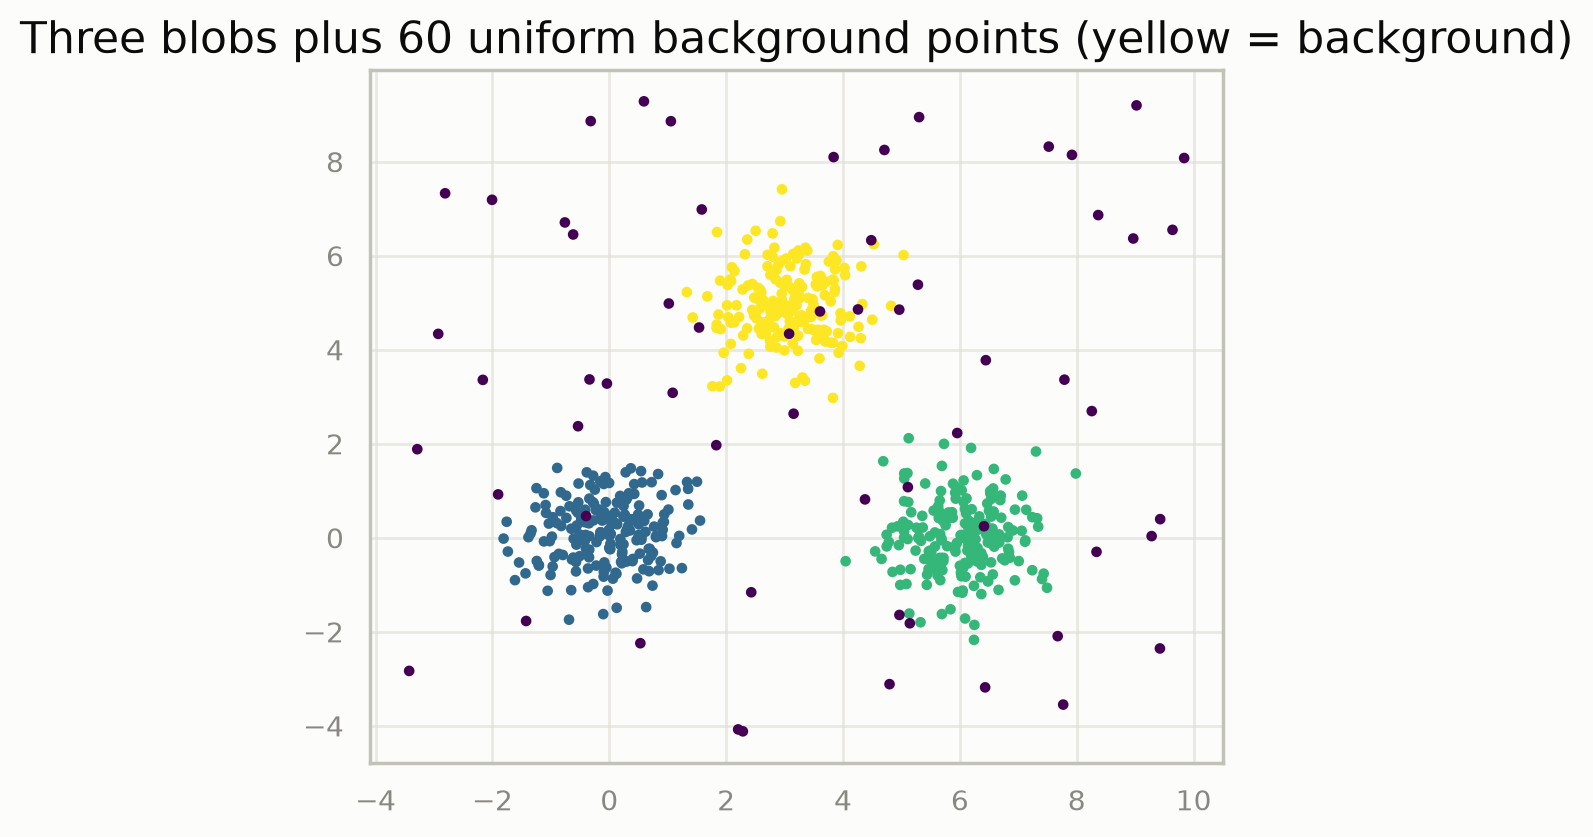

In [ ]:
_g = torch.Generator().manual_seed(SEED)
_centers = torch.tensor([[0.0, 0.0], [6.0, 0.0], [3.0, 5.0]])
_blobs = torch.cat([_c + 0.7 * torch.randn(200, 2, generator=_g) for _c in _centers])
_lo, _hi = _blobs.min(0).values - 2, _blobs.max(0).values + 2
_background = _lo + (_hi - _lo) * torch.rand(60, 2, generator=_g)

X_noise = torch.cat([_blobs, _background])
y_noise = torch.cat([torch.arange(3).repeat_interleave(200), torch.full((60,), -1)])  # -1 = background

plt.figure(figsize=(5.5, 4.5))
plt.scatter(X_noise[:, 0], X_noise[:, 1], c=y_noise, cmap='viridis', s=8)
plt.title('Three blobs plus 60 uniform background points (yellow = background)')
plt.gcf()

Fit an ordinary `GaussianMixture` and one with `noise=True`. With the noise component on, `predict` returns **`-1`** for the
points whose most probable "component" is the noise column -- the same convention as `HDBSCAN` and
`ClusteringMetrics(noise_label=-1)` -- and `weights_` holds the $K$ *component* weights, which now sum to
$1-\pi_0$ (`noise_weight_` is $\pi_0$).

In [ ]:
gmm_plain = GaussianMixture(n_components=3, random_state=SEED, max_iter=MAX_ITER, n_init=N_INIT).fit(X_noise)
gmm_noise = GaussianMixture(n_components=3, noise=True, random_state=SEED, max_iter=MAX_ITER, n_init=N_INIT).fit(X_noise)

pred_noise = gmm_noise.predict(X_noise)
_is_noise, _flagged = (y_noise == -1), (pred_noise == -1)
_kept = ~_is_noise & ~_flagged
print(f'estimated noise weight pi_0 = {float(gmm_noise.noise_weight_):.3f}  (true fraction {float(_is_noise.float().mean()):.3f})')
print(f'component weights sum to {float(gmm_noise.weights_.sum()):.3f}')
print(f'background points flagged as noise: {int((_is_noise & _flagged).sum())} of {int(_is_noise.sum())}')
print(f'ARI on the non-noise points: {ClusteringMetrics.adjusted_rand_score(y_noise[_kept], pred_noise[_kept]):.3f}')
print('mean covariance trace, plain vs noise model:',
      f'{float(torch.diagonal(gmm_plain.covariances_, dim1=-2, dim2=-1).sum(-1).mean()):.2f}',
      f'{float(torch.diagonal(gmm_noise.covariances_, dim1=-2, dim2=-1).sum(-1).mean()):.2f}')

estimated noise weight pi_0 = 0.090  (true fraction 0.091)
component weights sum to 0.910
background points flagged as noise: 43 of 60
ARI on the non-noise points: 1.000
mean covariance trace, plain vs noise model: 2.24 0.99


The plain model inflates its covariances to swallow the background (left); the noise model keeps them tight (right) (true trace of each
covariance is $2\times0.7^2\approx0.98$). The figure draws the 2-$\sigma$ ellipse of every component for both fits and colours
the points by the noise model's `noise_proba(X)`, the posterior probability that a point belongs to the uniform component.

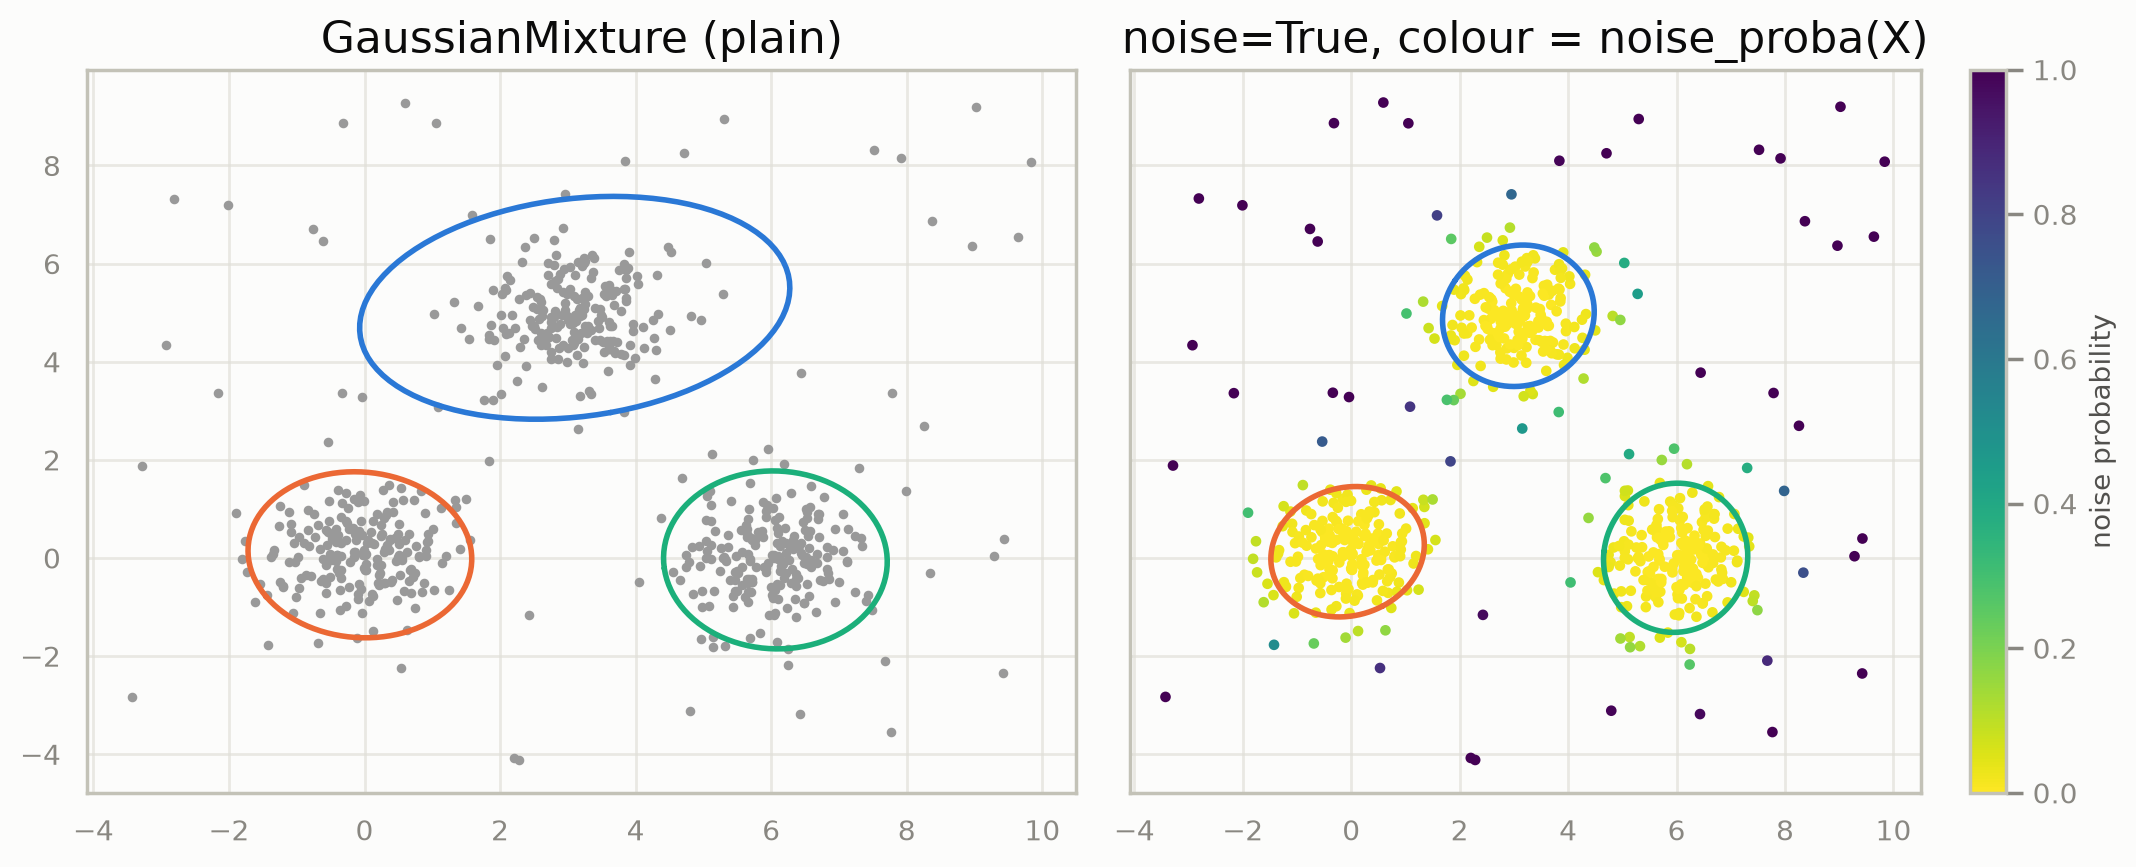

In [ ]:
def _ellipse(ax, mean, cov, color):
    _vals, _vecs = torch.linalg.eigh(cov)
    _t = torch.linspace(0, 2 * math.pi, 100)
    _pts = (_vecs @ torch.diag(2 * _vals.sqrt()) @ torch.stack([_t.cos(), _t.sin()])).T + mean
    ax.plot(_pts[:, 0], _pts[:, 1], color=color, lw=2)


_fig, _axes = plt.subplots(1, 2, figsize=(11, 4.5), sharex=True, sharey=True)
_axes[0].scatter(X_noise[:, 0], X_noise[:, 1], s=6, color='0.6')
for _k in range(3):
    _ellipse(_axes[0], gmm_plain.means_[_k], gmm_plain.covariances_[_k], CATEGORICAL_PALETTE[_k])
_axes[0].set_title('GaussianMixture (plain)')

_sc = _axes[1].scatter(X_noise[:, 0], X_noise[:, 1], c=gmm_noise.noise_proba(X_noise), cmap='viridis_r', s=8, vmin=0, vmax=1)
for _k in range(3):
    _ellipse(_axes[1], gmm_noise.means_[_k], gmm_noise.covariances_[_k], CATEGORICAL_PALETTE[_k])
_axes[1].set_title('noise=True, colour = noise_proba(X)')
_fig.colorbar(_sc, ax=_axes[1], label='noise probability')
plt.tight_layout()
_fig

### Starting from a density-based guess

`noise_init` seeds the noise column from a per-point flag. A boolean tensor means "`True` = noise"; any other dtype is read as
cluster labels with `-1` = noise, so the output of `HDBSCAN` can be passed as it is. The initial means and covariances are then
computed from the unflagged points only, and `noise_prior` is replaced by the flagged fraction.

In [ ]:
_hdb = HDBSCAN(min_cluster_size=30).fit(X_noise)
_labels = torch.as_tensor(_hdb.labels_)
gmm_hdb_init = GaussianMixture(n_components=3, noise=True, noise_init=_labels, random_state=SEED,
                               max_iter=MAX_ITER).fit(X_noise)
print(f'HDBSCAN flagged {int((_labels == -1).sum())} points; fitted pi_0 = {float(gmm_hdb_init.noise_weight_):.3f}')
print('noise_proba shape:', tuple(gmm_hdb_init.noise_proba(X_noise).shape),
      ' predict_proba shape:', tuple(gmm_hdb_init.predict_proba(X_noise).shape))
_s, _idx = gmm_hdb_init.sample(2000)
print(f'sample(): {int((_idx == -1).sum())} of 2000 draws are noise (index -1), uniform in the fit bounding box')

HDBSCAN flagged 44 points; fitted pi_0 = 0.090
noise_proba shape: (660,)  predict_proba shape: (660, 4)
sample(): 182 of 2000 draws are noise (index -1), uniform in the fit bounding box


## 2. Missing values

With `missing='em'`, `NaN` entries are treated as **missing at random** and the likelihood is maximised over the entries that
*were* observed. For a row with observed block $o$ and missing block $m$, and component $k$:

- the E-step uses the **marginal** density $\mathcal N(x_o;\mu_{k,o},\Sigma_{k,oo})$;
- the M-step fills the hole with the **conditional mean**
  $\hat x_m=\mu_{k,m}+\Sigma_{k,mo}\Sigma_{k,oo}^{-1}(x_o-\mu_{k,o})$ and adds the **conditional covariance**
  $C_k=\Sigma_{k,mm}-\Sigma_{k,mo}\Sigma_{k,oo}^{-1}\Sigma_{k,om}$ to the second moment, so the variance is not underestimated.

Rows are grouped by missingness pattern, so the cost is one batched solve per pattern, not per row. Below, 20% of the entries
of a two-cluster dataset are deleted completely at random (keeping at least one observed entry per row: a row with nothing observed
carries no information and is rejected).

In [ ]:
_g = torch.Generator().manual_seed(SEED + 1)
_a = torch.randn(300, 2, generator=_g) * 0.8
_b = torch.randn(300, 2, generator=_g) * 0.8 + torch.tensor([4.0, 3.0])
X_complete = torch.cat([_a, _b])
y_missing = torch.arange(2).repeat_interleave(300)

holes_mask = torch.rand(X_complete.shape, generator=_g) < 0.2
holes_mask[holes_mask.all(1), 0] = False                 # keep one observed entry in every row
X_holes = X_complete.clone()
X_holes[holes_mask] = float('nan')
print(f'{int(holes_mask.sum())} of {X_holes.numel()} entries are missing; {int(holes_mask.any(1).sum())} rows are incomplete')

211 of 1200 entries are missing; 211 rows are incomplete


In [ ]:
gmm_complete = GaussianMixture(n_components=2, random_state=SEED, max_iter=MAX_ITER, n_init=N_INIT).fit(X_complete)
gmm_missing = GaussianMixture(n_components=2, missing='em', random_state=SEED, max_iter=MAX_ITER, n_init=N_INIT).fit(X_holes)

print('means, complete data :', gmm_complete.means_.numpy().round(2).tolist())
print('means, 20% missing   :', gmm_missing.means_.numpy().round(2).tolist())
print(f'ARI, complete data : {ClusteringMetrics.adjusted_rand_score(y_missing, gmm_complete.predict(X_complete)):.3f}')
print(f'ARI, 20% missing   : {ClusteringMetrics.adjusted_rand_score(y_missing, gmm_missing.predict(X_holes)):.3f}   (predict accepts rows with NaN)')

means, complete data : [[-0.05000000074505806, 0.03999999910593033], [3.9600000381469727, 2.940000057220459]]
means, 20% missing   : [[-0.03999999910593033, 0.05000000074505806], [3.9800000190734863, 2.9600000381469727]]
ARI, complete data : 1.000
ARI, 20% missing   : 0.980   (predict accepts rows with NaN)


`impute(X)` returns `X` with every `NaN` replaced by the posterior-weighted conditional mean $\sum_k\tau_{ik}\hat x_{ik}$; observed entries
are untouched. Compared with filling each column with its mean, the model-based imputation uses the row's *other* coordinates and the cluster
structure.

RMSE of the 211 imputed entries: model-based 0.85  vs  column mean 1.85


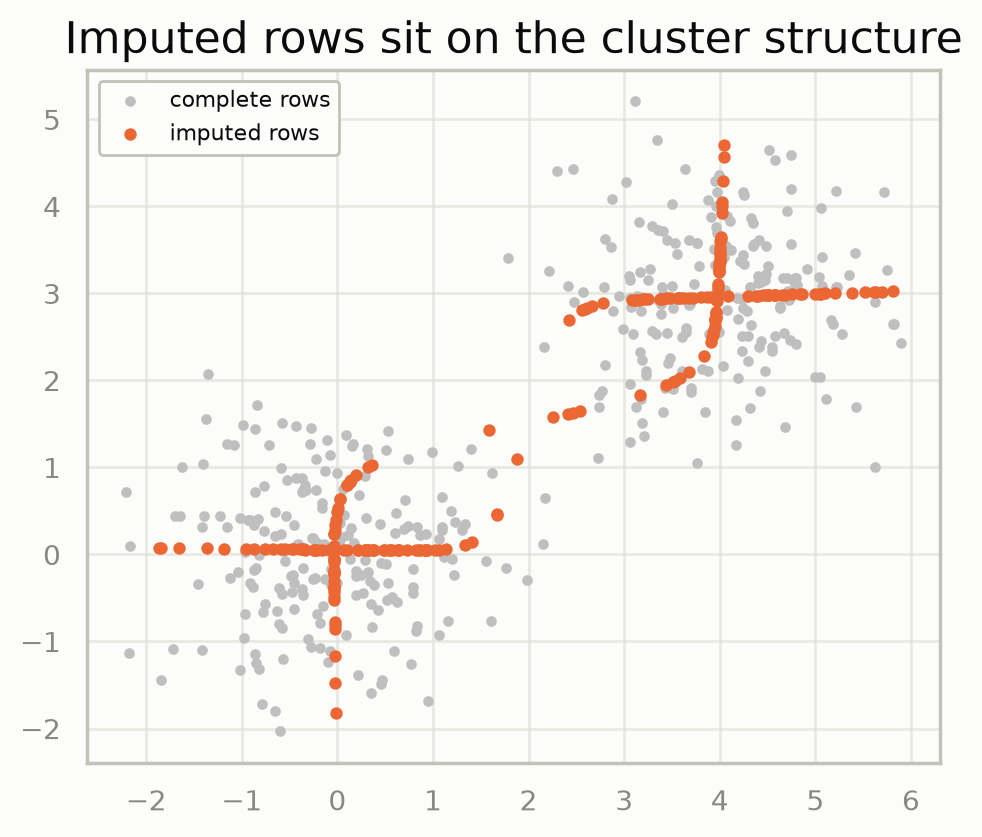

In [ ]:
X_imputed = gmm_missing.impute(X_holes)
_col_mean = torch.nanmean(X_holes, dim=0).expand_as(X_holes)
_rmse_model = float(((X_imputed - X_complete)[holes_mask] ** 2).mean().sqrt())
_rmse_mean = float(((_col_mean - X_complete)[holes_mask] ** 2).mean().sqrt())
print(f'RMSE of the {int(holes_mask.sum())} imputed entries: model-based {_rmse_model:.2f}  vs  column mean {_rmse_mean:.2f}')

_incomplete = holes_mask.any(1)
plt.figure(figsize=(5.5, 4.5))
plt.scatter(X_complete[~_incomplete, 0], X_complete[~_incomplete, 1], s=8, color='0.75', label='complete rows')
plt.scatter(X_imputed[_incomplete, 0], X_imputed[_incomplete, 1], s=12, color=CATEGORICAL_PALETTE[1], label='imputed rows')
plt.legend()
plt.title('Imputed rows sit on the cluster structure')
plt.gcf()

## 3. Marginals and conditionals: Gaussian mixture regression

A fitted `GaussianMixture` is a joint density, so it can answer any question about subsets of coordinates.

- `gmm.marginal(dims)` returns a new `GaussianMixture` over the chosen coordinates (diagonal, spherical and tied types keep their type; the
  parametrised GPCM codes become `full`).
- `gmm.condition(x_obs, obs_dims)` returns a `ConditionalGaussianMixture`: for every row of `x_obs`, the distribution of the *remaining* coordinates,

$$
p(y\mid x_{o,i})=\sum_{k}w_{ik}\,\mathcal N\big(y;\ m_{ik},\ C_k\big),\qquad
w_{ik}\propto\pi_k\mathcal N(x_{o,i};\mu_{k,o},\Sigma_{k,oo}),
$$

with $m_{ik}=\mu_{k,m}+\Sigma_{k,mo}\Sigma_{k,oo}^{-1}(x_{o,i}-\mu_{k,o})$ and $C_k=\Sigma_{k,mm}-\Sigma_{k,mo}\Sigma_{k,oo}^{-1}\Sigma_{k,om}$.
The weights depend on the observed values, the conditional covariances do not. `mean()` is **Gaussian mixture regression**:
$\mathbb E[y\mid x_o]=\sum_kw_{ik}m_{ik}$.

Fit eight components to noisy samples of $y=\sin 2x$ and regress $y$ on $x$.

weights (200, 8), means (200, 8, 1), covariances (8, 1, 1)
RMSE of the GMR curve against the noiseless sin(2x): 0.045


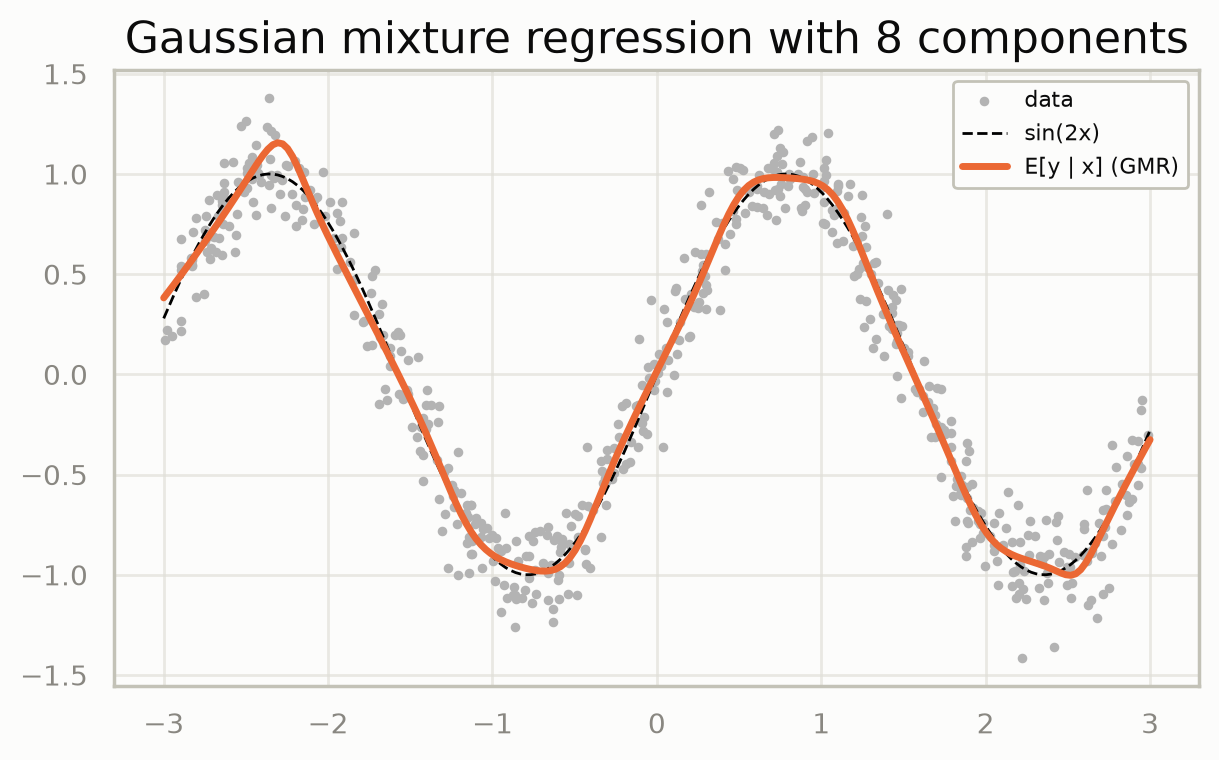

In [ ]:
_g = torch.Generator().manual_seed(SEED + 2)
_x = torch.rand(600, 1, generator=_g) * 6 - 3
_y = torch.sin(2 * _x) + 0.15 * torch.randn(600, 1, generator=_g)
XY_sine = torch.cat([_x, _y], dim=1)

gmm_joint = GaussianMixture(n_components=8, random_state=SEED, max_iter=MAX_ITER, n_init=N_INIT).fit(XY_sine)

x_grid = torch.linspace(-3, 3, 200)[:, None]
cond_sine = gmm_joint.condition(x_grid, [0])          # condition on coordinate 0 (x)
gmr_mean = cond_sine.mean()[:, 0]
_rmse = float(((gmr_mean - torch.sin(2 * x_grid[:, 0])) ** 2).mean().sqrt())
print(f'weights {tuple(cond_sine.weights_.shape)}, means {tuple(cond_sine.means_.shape)}, covariances {tuple(cond_sine.covariances_.shape)}')
print(f'RMSE of the GMR curve against the noiseless sin(2x): {_rmse:.3f}')

plt.figure(figsize=(7, 4))
plt.scatter(XY_sine[:, 0], XY_sine[:, 1], s=6, color='0.7', label='data')
plt.plot(x_grid[:, 0], torch.sin(2 * x_grid[:, 0]), 'k--', lw=1, label='sin(2x)')
plt.plot(x_grid[:, 0], gmr_mean, color=CATEGORICAL_PALETTE[1], lw=2.5, label='E[y | x] (GMR)')
plt.legend()
plt.title('Gaussian mixture regression with 8 components')
plt.gcf()

The conditional is a whole *distribution*, not just a mean, and it can be multimodal. On an X-shaped dataset ($y=\pm x$ with equal
probability) the regression mean at $x>0$ is close to zero -- a value the data almost never take -- while the conditional density has two clear
peaks. `log_prob(Y)` evaluates it on a grid and `as_gmm(i)` hands over the conditional of row `i` as an ordinary one-dimensional `GaussianMixture`.

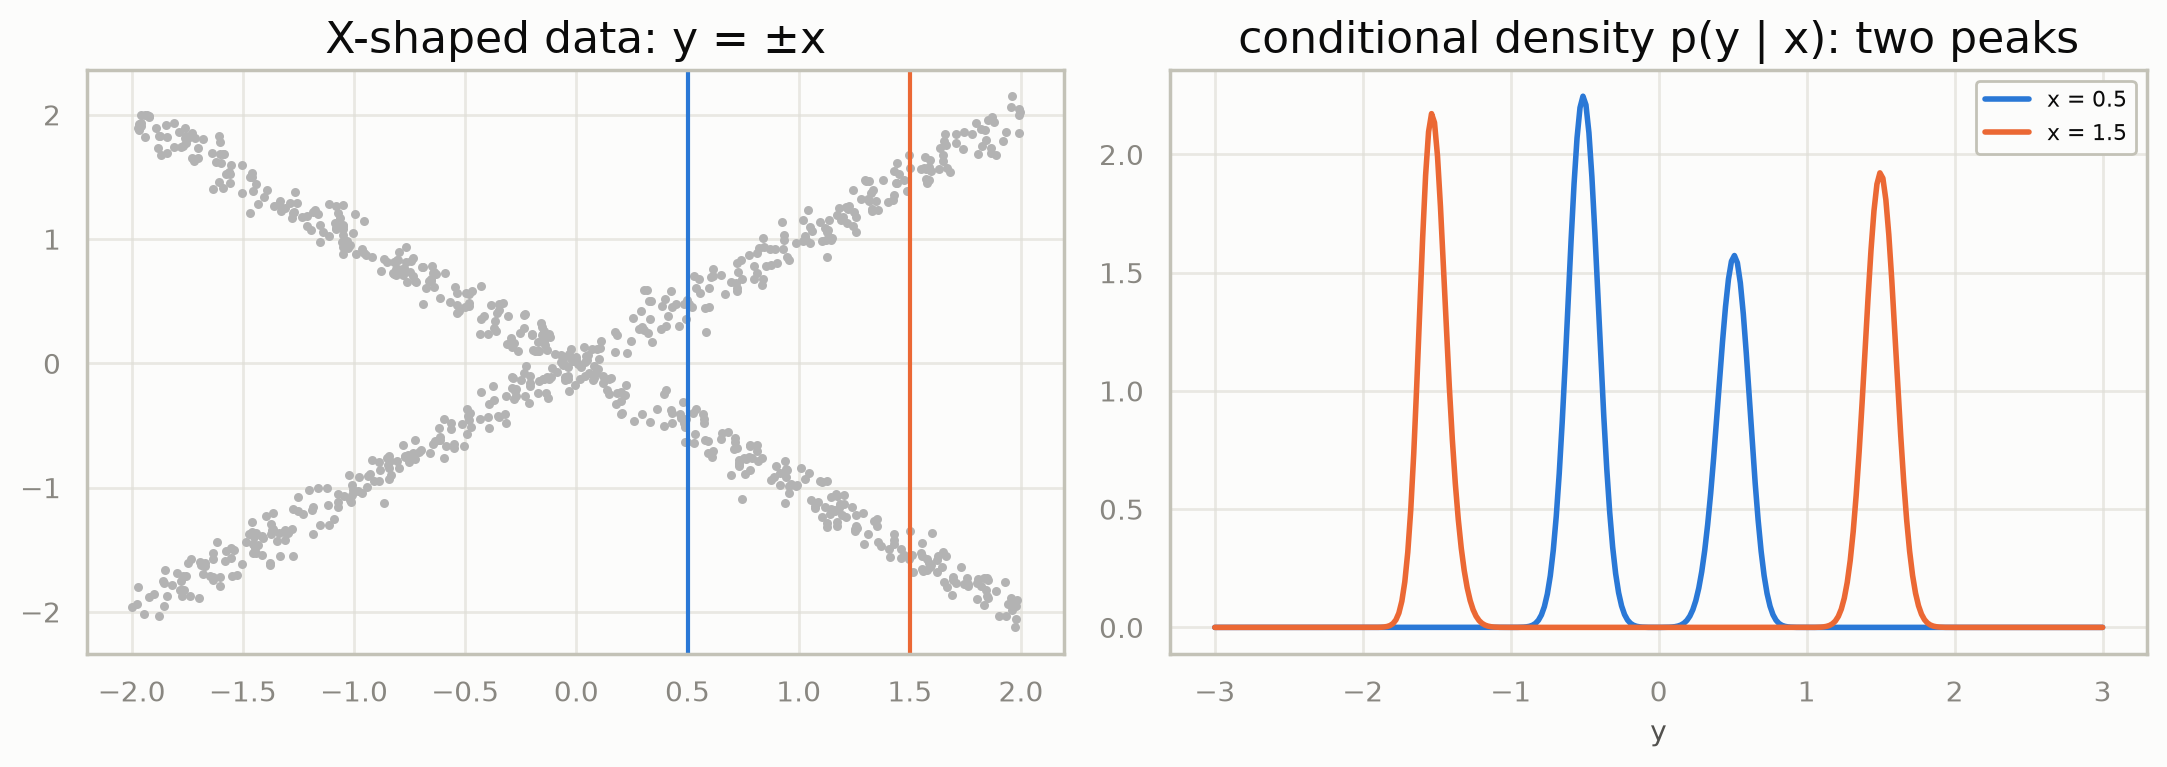

In [ ]:
_g = torch.Generator().manual_seed(SEED + 3)
_t = torch.rand(800, 1, generator=_g) * 4 - 2
_sign = torch.where(torch.rand(800, 1, generator=_g) < 0.5, 1.0, -1.0)
XY_cross = torch.cat([_t, _sign * _t + 0.1 * torch.randn(800, 1, generator=_g)], dim=1)

gmm_cross = GaussianMixture(n_components=6, random_state=SEED, max_iter=MAX_ITER, n_init=N_INIT).fit(XY_cross)
_x_query = torch.tensor([[0.5], [1.5]])
cond_cross = gmm_cross.condition(_x_query, [0])        # one conditional mixture per query row

y_axis = torch.linspace(-3, 3, 300)[:, None]
_fig, _axes = plt.subplots(1, 2, figsize=(11, 4))
_axes[0].scatter(XY_cross[:, 0], XY_cross[:, 1], s=5, color='0.7')
for _i, _xq in enumerate(_x_query[:, 0].tolist()):
    _axes[0].axvline(_xq, color=CATEGORICAL_PALETTE[_i], lw=1.5)
    _single = gmm_cross.condition(torch.tensor([[_xq]]), [0])      # a single-row conditional broadcasts against the whole grid
    _axes[1].plot(y_axis[:, 0], _single.log_prob(y_axis).exp(), color=CATEGORICAL_PALETTE[_i], lw=2, label=f'x = {_xq}')
_axes[0].set_title('X-shaped data: y = ±x')
_axes[1].set_title('conditional density p(y | x): two peaks')
_axes[1].set_xlabel('y')
_axes[1].legend()
plt.tight_layout()
_fig

In [ ]:
_conditional_at_1_5 = cond_cross.as_gmm(1)
print('as_gmm(1):', type(_conditional_at_1_5).__name__, 'with', _conditional_at_1_5.n_components, 'components over the missing coordinate')
print('regression mean at x = 1.5 :', f'{float(cond_cross.mean()[1, 0]):+.2f}   (mixture weights {cond_cross.weights_[1].numpy().round(2).tolist()})')
print('conditional component means:', cond_cross.means_[1, :, 0].numpy().round(2).tolist())

as_gmm(1): GaussianMixture with 6 components over the missing coordinate
regression mean at x = 1.5 : -0.00   (mixture weights [0.5, 0.2199999988079071, 0.0, 0.0, 0.0, 0.27000001072883606])
conditional component means: [1.5, -1.4800000190734863, 1.2400000095367432, -1.4900000095367432, 1.5700000524520874, -1.5499999523162842]


## 4. Controlling what EM changes: `frozen_components` and `sample_weight`

**Frozen components.** `frozen_components=[k, ...]` keeps those components' means and covariances (or `dof_` / `kappa_` for the other families)
at their **initial** values for the whole fit; the mixing weights still update (and so does the noise weight). Use it to pin a component you already
know -- a calibrated background, a reference population -- and let the others adapt around it. Priors never shrink a frozen component and SEM never
re-seeds it. The initial values come from `init_means` / `init_covariances`.

In [ ]:
_g = torch.Generator().manual_seed(SEED + 4)
X_pair = torch.cat([torch.randn(300, 2, generator=_g) * 0.7, torch.randn(300, 2, generator=_g) * 0.7 + torch.tensor([4.0, 0.0])])
init_pair = torch.tensor([[0.0, 0.0], [4.5, 0.5]])          # slightly off for the second component

gmm_frozen = GaussianMixture(n_components=2, init_means=init_pair, frozen_components=[0], random_state=SEED,
                             max_iter=MAX_ITER).fit(X_pair)
print('component 0 (frozen)  mean:', gmm_frozen.means_[0].tolist(), '  -> exactly the initial value')
print('component 1 (free)    mean:', gmm_frozen.means_[1].numpy().round(2).tolist(), '  (moved from', init_pair[1].tolist(), 'towards the data)')
print('mixing weights still update:', gmm_frozen.weights_.numpy().round(3).tolist(), ' sum =', round(float(gmm_frozen.weights_.sum()), 6))

component 0 (frozen)  mean: [0.0, 0.0]   -> exactly the initial value
component 1 (free)    mean: [4.019999980926514, -0.009999999776482582]   (moved from [4.5, 0.5] towards the data)
mixing weights still update: [0.5009999871253967, 0.49900001287460327]  sum = 1.0


**Sample weights.** `fit(X, sample_weight=w)` with $w\in\mathbb R_{\ge0}^n$ counts row $i$ as $w_i$ observations: responsibilities are scaled by $w_i$
before the sufficient statistics, so $n_k$, $s_1$, $s_2$ and the mixing weights are weighted. Integer weights are therefore *equivalent to duplicating
rows* -- a handy way to fit pre-aggregated data -- and a weight of 0 removes a row. Per-feature weights of shape $(n,d)$ are accepted by the models whose
likelihood factorises over features (`'diag'` / `'spherical'` Gaussians, diagonal Student-t); a zero entry hides one feature of one row.

In [ ]:
_w = torch.ones(len(X_pair))
_w[:300] = 3.0                                          # the first blob counts three times
gmm_weighted = GaussianMixture(n_components=2, init_means=init_pair, random_state=SEED, max_iter=MAX_ITER).fit(X_pair, sample_weight=_w)
gmm_duplicated = GaussianMixture(n_components=2, init_means=init_pair, random_state=SEED, max_iter=MAX_ITER).fit(
    torch.cat([X_pair[:300]] * 3 + [X_pair[300:]]))

print('weights with sample_weight :', gmm_weighted.weights_.numpy().round(4).tolist())
print('weights with duplicated rows:', gmm_duplicated.weights_.numpy().round(4).tolist())
print('largest difference in the fitted means:', f'{float((gmm_weighted.means_ - gmm_duplicated.means_).abs().max()):.1e}', '(float32 round-off)')

weights with sample_weight : [0.7505999803543091, 0.24940000474452972]
weights with duplicated rows: [0.7505999803543091, 0.24940000474452972]
largest difference in the fitted means: 1.1e-05 (float32 round-off)


## 5. Bring your own component: the protocol and `GenericMixture`

Every family in `tgmm` is a `BaseMixture`, and `GenericMixture` is the one that takes its components from you. A component is any object that
implements three methods (the shape pomegranate popularised):

| method | job |
| --- | --- |
| `log_probability(X)` | return $\log f_k(x_i)$, shape `(n,)` |
| `summarize(X, sample_weight)` | **accumulate** weighted statistics of one chunk of data (`sample_weight` = responsibility $\times$ row weight) |
| `from_summaries()` | update the parameters from everything summarised, then reset the accumulators |

The M-step calls `summarize` once per data chunk and `from_summaries` once, so `batch_size` works for free. Optional members are `sample(n)`,
`n_parameters()` (needed for `bic`/`aic`/`icl`) and a `frozen` flag. A plain `torch.nn.Module` with a `log_prob(X)` method is also accepted: it is
updated by a few L-BFGS steps that are kept only if they improve the expected complete-data log-likelihood.

Here is a tiny mixture of an **exponential** (waiting times) and a **normal** (a burst around 6) over positive data -- neither is a `GaussianMixture` component.

In [ ]:
class Exponential:
    """f(x) = rate * exp(-rate x) on x >= 0; the weighted M-step is rate = sum(w) / sum(w x)."""

    def __init__(self, rate):
        self.rate = torch.tensor(float(rate), dtype=torch.float64)
        self._reset()

    def _reset(self):
        self._sw = torch.zeros((), dtype=torch.float64)
        self._sx = torch.zeros((), dtype=torch.float64)

    def log_probability(self, X):
        _x = X[:, 0]
        return torch.where(_x >= 0, torch.log(self.rate) - self.rate * _x, torch.full_like(_x, -1e30))

    def summarize(self, X, sample_weight):
        _w = sample_weight.to(torch.float64)
        self._sw = self._sw + _w.sum()
        self._sx = self._sx + (_w * X[:, 0]).sum()

    def from_summaries(self):
        if float(self._sw) > 1e-12:
            self.rate = self._sw / self._sx.clamp(min=1e-12)
        self._reset()

    def sample(self, n):
        return torch.distributions.Exponential(self.rate).sample((n, 1))

    def n_parameters(self):
        return 1


class Normal1D:
    """N(mean, var) with the usual weighted-moment M-step."""

    def __init__(self, mean, var):
        self.mean = torch.tensor([float(mean)], dtype=torch.float64)
        self.var = torch.tensor([float(var)], dtype=torch.float64)
        self._reset()

    def _reset(self):
        self._sw = torch.zeros((), dtype=torch.float64)
        self._s1 = torch.zeros(1, dtype=torch.float64)
        self._s2 = torch.zeros(1, dtype=torch.float64)

    def log_probability(self, X):
        return (-0.5 * ((X - self.mean) ** 2 / self.var + torch.log(2 * math.pi * self.var))).sum(1)

    def summarize(self, X, sample_weight):
        _w = sample_weight.to(torch.float64)
        self._sw = self._sw + _w.sum()
        self._s1 = self._s1 + (_w[:, None] * X).sum(0)
        self._s2 = self._s2 + (_w[:, None] * X * X).sum(0)

    def from_summaries(self):
        if float(self._sw) > 1e-12:
            self.mean = self._s1 / self._sw
            self.var = (self._s2 / self._sw - self.mean ** 2).clamp(min=0) + 1e-6
        self._reset()

    def sample(self, n):
        return self.mean + self.var.sqrt() * torch.randn(n, 1, dtype=torch.float64)

    def n_parameters(self):
        return 2

weights [0.671, 0.329]   (true 0.667 / 0.333)
exponential rate 1.04 (true 1.0);  normal mean 6.04, variance 0.39 (true 6.0 / 0.49)
converged in 4 iterations; BIC = 2835.4; 3 samples drawn from the fitted components


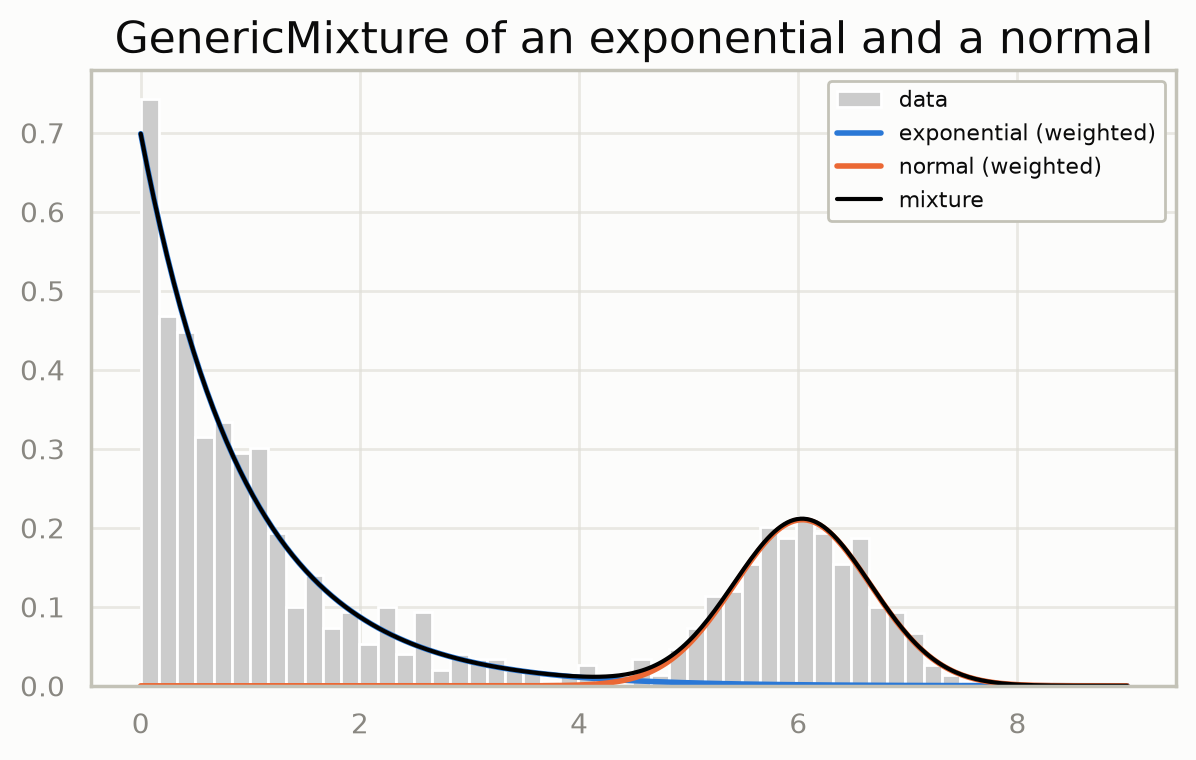

In [ ]:
_g = torch.Generator().manual_seed(SEED + 5)
_waits = torch.distributions.Exponential(torch.tensor(1.0, dtype=torch.float64)).sample((600, 1))
_burst = 6 + 0.7 * torch.randn(300, 1, generator=_g, dtype=torch.float64)
X_wait = torch.cat([_waits, _burst])

generic = GenericMixture(components=[Exponential(0.5), Normal1D(5.0, 1.0)], random_state=SEED, max_iter=MAX_ITER).fit(X_wait)
print(f'weights {generic.weights_.numpy().round(3).tolist()}   (true 0.667 / 0.333)')
print(f'exponential rate {float(generic.components_[0].rate):.2f} (true 1.0);  normal mean {float(generic.components_[1].mean):.2f}, '
      f'variance {float(generic.components_[1].var):.2f} (true 6.0 / 0.49)')
print(f'converged in {generic.n_iter_} iterations; BIC = {generic.bic(X_wait):.1f}; {generic.sample(3)[0].shape[0]} samples drawn from the fitted components')

_grid = torch.linspace(0, 9, 300, dtype=torch.float64)[:, None]
_pdf_total = generic.score_samples(_grid).exp()
plt.figure(figsize=(7, 4))
plt.hist(X_wait[:, 0], bins=50, density=True, color='0.8', label='data')
for _k, _name in enumerate(['exponential', 'normal']):
    plt.plot(_grid[:, 0], generic.weights_[_k] * generic.components_[_k].log_probability(_grid).exp(), lw=2,
             color=CATEGORICAL_PALETTE[_k], label=f'{_name} (weighted)')
plt.plot(_grid[:, 0], _pdf_total, 'k', lw=1.5, label='mixture')
plt.legend()
plt.title('GenericMixture of an exponential and a normal')
plt.gcf()

## Summary

- `noise=True` adds a uniform component $\pi_0/V$: `predict` returns `-1` for noise, `noise_proba(X)` gives the probability, `weights_` sums to $1-\pi_0$, and
  the component covariances are no longer inflated by background points. `noise_init` accepts a boolean mask or `HDBSCAN` labels.
- `missing='em'` maximises the likelihood of the observed entries: marginal densities in the E-step, conditional means and covariances in the M-step, `impute`
  for the filled-in data, and every consumer (`predict`, `score`, `bic`, ...) accepts rows with `NaN`.
- `marginal(dims)` and `condition(x_obs, obs_dims)` turn a fitted `GaussianMixture` into marginal and conditional distributions; `mean()` is Gaussian mixture
  regression and the conditional can be multimodal where a regression mean is misleading.
- `frozen_components` pins components at their initial parameters, and `sample_weight` counts rows (integer weights equal duplication; per-feature weights for factorising models).
- `GenericMixture` fits any family that implements `log_probability`, `summarize` and `from_summaries` (or any `nn.Module` with `log_prob`), with `batch_size`,
  `sample_weight`, frozen components and information criteria included.

**Next:** [18 -- Semi-Supervised and Positive-Unlabeled Fitting](18_semi_supervised_pu.ipynb) for another way of steering the fit, or the
[user guide](../user-guide/noise-missing-conditioning.md) for the equations behind this tutorial.